# 01 — EDA: target balance & feature signal

Exploratory analysis for the repeat-purchase task. All data-shaping logic is imported from
`src/retail_repeat` so this notebook can never drift from training/serving. We look at:

1. The cleaning effect (how many lines survive as qualifying purchases)
2. **Target balance** per split (is the problem imbalanced?)
3. Feature distributions, split by label
4. The recency → repeat-rate relationship (the signal our recency baseline will exploit)

Context: historical UK gift-wholesaler, 2010-12 → 2011-12. Not generalisable to other markets.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / 'src'))
from retail_repeat import config, data, features

pd.set_option('display.width', 140)
FIG = config.FIGURES_DIR
FIG.mkdir(parents=True, exist_ok=True)
print('windows:', config.LOOKBACK_DAYS, 'day lookback /', config.HORIZON_DAYS, 'day horizon')
print('cutoffs:', config.CUTOFFS)

windows: 90 day lookback / 30 day horizon
cutoffs: {'train': '2011-06-01', 'val': '2011-08-01', 'test': '2011-10-01'}


In [2]:
raw = data.load_transactions()
clean, stats = data.clean_transactions(raw)
print(f'raw rows:    {stats.rows_in:,}')
print(f'clean rows:  {stats.rows_out:,}  ({100*stats.rows_out/stats.rows_in:.1f}% kept)')
print(f'customers:   {stats.extra["distinct_customers"]:,}')
print(f'orders:      {stats.extra["distinct_orders"]:,}')

raw rows:    541,909
clean rows:  390,859  (72.1% kept)
customers:   4,334
orders:      18,401


## Target balance

The positive class = customers who buy again within 30 days. We check each chronological split.

,eligible,positives,pos_rate
train,1957,634,32.4%
val,2019,641,31.7%
test,2145,755,35.2%


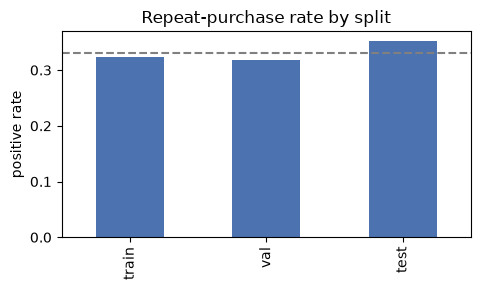

In [3]:
snapshots = {s: features.build_snapshot(clean, c) for s, c in config.CUTOFFS.items()}
bal = pd.DataFrame({
    s: {
        'eligible': len(df),
        'positives': int(df.label.sum()),
        'pos_rate': df.label.mean(),
    } for s, df in snapshots.items()
}).T
bal['eligible'] = bal['eligible'].astype(int)
bal['positives'] = bal['positives'].astype(int)
display(bal.assign(pos_rate=lambda d: (100*d.pos_rate).round(1).astype(str)+'%'))

ax = bal['pos_rate'].plot(kind='bar', color='#4c72b0', figsize=(5,3))
ax.set_ylabel('positive rate'); ax.set_title('Repeat-purchase rate by split')
ax.axhline(bal['pos_rate'].mean(), ls='--', c='grey')
plt.tight_layout(); plt.savefig(FIG/'target_balance.png', dpi=110); plt.show()

**Read-out:** roughly **1 in 3** eligible customers repurchases within 30 days. This is a *mild*
imbalance — not a rare-event problem. A model that predicts “never repurchase” would be ~67% accurate
yet useless, which is exactly why we report ROC-AUC / average precision, not accuracy.

## Feature distributions by label (train split)

       recency_days  n_orders  total_spend  avg_order_value  n_distinct_products
count       1957.00   1957.00      1957.00          1957.00              1957.00
mean          35.00      1.99       845.17           391.27                33.01
std           25.24      2.36      2233.42           668.05                40.47
min            0.00      1.00         2.90             2.90                 1.00
25%           13.00      1.00       225.15           176.61                11.00
50%           26.00      1.00       391.52           299.48                22.00
75%           55.00      2.00       790.10           432.48                41.00
max           89.00     41.00     52454.10         21535.90               680.00


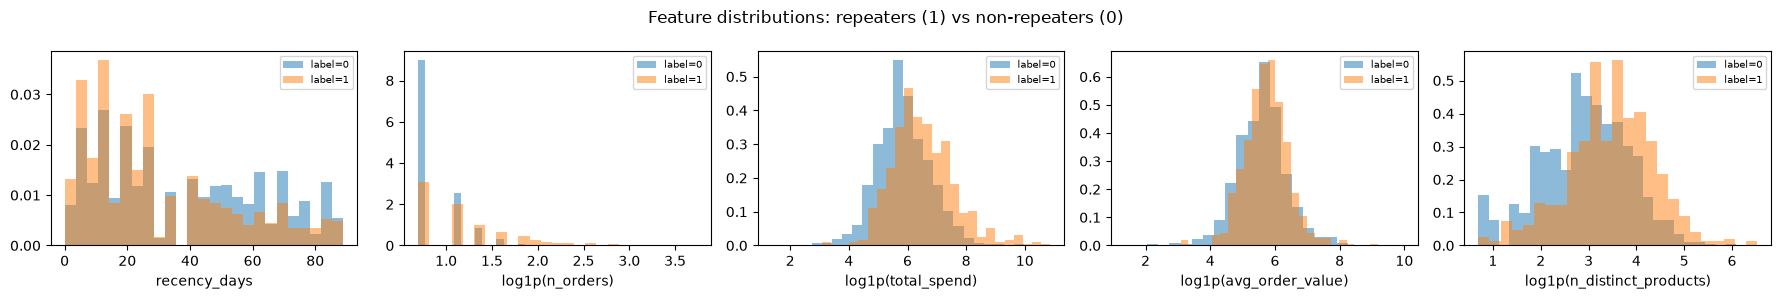

In [4]:
train = snapshots['train']
print(train[config.FEATURE_COLUMNS].describe().round(2))

fig, axes = plt.subplots(1, len(config.FEATURE_COLUMNS), figsize=(18, 3))
for ax, col in zip(axes, config.FEATURE_COLUMNS):
    for lbl, grp in train.groupby('label'):
        vals = grp[col]
        # log scale for the heavy-tailed monetary/count features
        if col in {'total_spend', 'avg_order_value', 'n_distinct_products', 'n_orders'}:
            vals = np.log1p(vals)
            ax.set_xlabel('log1p('+col+')')
        else:
            ax.set_xlabel(col)
        ax.hist(vals, bins=25, alpha=0.5, label=f'label={lbl}', density=True)
    ax.legend(fontsize=7)
plt.suptitle('Feature distributions: repeaters (1) vs non-repeaters (0)')
plt.tight_layout(); plt.savefig(FIG/'feature_dists_by_label.png', dpi=110); plt.show()

## Recency → repeat rate (the baseline signal)

Classic RFM intuition: customers who bought **recently** are more likely to buy again. If this holds,
a simple recency rule is a legitimate baseline for the ML models to beat.

,repeat_rate,customers
recency_bin,,
"[0, 7)",41.7%,206
"[7, 14)",39.5%,311
"[14, 30)",37.5%,526
"[30, 60)",28.3%,473
"[60, 90)",21.3%,441


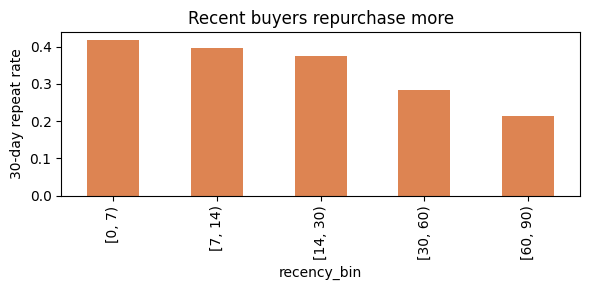

In [5]:
bins = [0, 7, 14, 30, 60, 90]
train = train.assign(recency_bin=pd.cut(train['recency_days'], bins=bins, right=False))
rate_by_rec = train.groupby('recency_bin', observed=True)['label'].agg(['mean', 'size'])
rate_by_rec.columns = ['repeat_rate', 'customers']
display(rate_by_rec.assign(repeat_rate=lambda d: (100*d.repeat_rate).round(1).astype(str)+'%'))

ax = rate_by_rec['repeat_rate'].plot(kind='bar', color='#dd8452', figsize=(6,3))
ax.set_ylabel('30-day repeat rate'); ax.set_title('Recent buyers repurchase more')
plt.tight_layout(); plt.savefig(FIG/'recency_vs_repeat.png', dpi=110); plt.show()

## Takeaways
- Target is mildly imbalanced (~32–35% positive) → evaluate with ROC-AUC & average precision, not accuracy.
- Monetary/count features are heavy-tailed → logistic regression will want scaling; trees won't care.
- Recency carries clear signal → a recency rule is a fair baseline. Next milestone builds the baselines.

In [5]:
# --- Lookback experiment: 90 days vs 30 days, same cutoff ---
from importlib import reload
from retail_repeat import config, features

def summarize(label, snap):
    n = len(snap)
    pos = int(snap["label"].sum())
    print(f"{label:>10}: eligible={n:>5,}  positives={pos:>4}  pos_rate={pos/n:6.1%}")

# 90-day version (our default)
config.LOOKBACK_DAYS = 90
snap90 = features.build_snapshot(clean, "2011-06-01")
summarize("90-day", snap90)

# 30-day version
config.LOOKBACK_DAYS = 30
snap30 = features.build_snapshot(clean, "2011-06-01")
summarize("30-day", snap30)

# IMPORTANT: put the config back so the rest of the project behaves normally
config.LOOKBACK_DAYS = 90
print("\nreset LOOKBACK_DAYS ->", config.LOOKBACK_DAYS)

    90-day: eligible=1,957  positives= 634  pos_rate= 32.4%
    30-day: eligible=1,043  positives= 406  pos_rate= 38.9%

reset LOOKBACK_DAYS -> 90


In [ ]:
for 90 day the pos_rate is 32.4 and for 30 day the pos_rate is 38.9% which the customers who recently buy the products are the one who are also retunring again . Explain to me further is my explaination does not hold 